In [1]:
using Plots                          # Plotting
using CSV, DataFrames, JLD2          # Data handling
using LinearAlgebra, StatsBase       # Linear algebra, statistics
using Random, Statistics             # Random number generation, basic statistics
using LaTeXStrings                   # LaTeX support for plots
using Revise                          # Live code reloading

using StaticArrays, LazySets          # Efficient arrays, set operations
using Interpolations, LinearInterpolations  # Interpolation utilities
using SpatiotemporalGPs               # Gaussian processes
using DifferentialEquations, ForwardDiff # Differential equations, automatic differentiation
using Distributions, StatsPlots, SpecialFunctions, Glob # Wind Transformatoins


In [2]:
# Import modules
include("../../../src/jordan_lake_domain.jl")
# include("../../../src/stgpkf.jl")
include("../../../src/kf.jl")
include("../../../src/ngpkf.jl")
include("../../../src/SyntheticData.jl")
include("../../../src/ergodic.jl")
include("../../../src/variograms.jl")
include("../../../src/SOC_Controller.jl")
include("../../../src/simulator_spatial.jl")
include("../../../src/simulator_ST.jl")
include("../../../src/Convex_bound_avoidance.jl")
include("../../../src/transects.jl")

┌ Warning: Replacing docs for `Main.Variograms.hp_fit :: Tuple{Any}` in module `Main.Variograms`
└ @ Base.Docs docs\Docs.jl:243


Main.Transects

In [3]:
# Plot Settings
plot_font = "Computer Modern"
default(
    fontfamily=plot_font,
    linewidth=2,
    guidefontsize=14,
    tickfontsize=14,
    legendfontsize=10,
    titlefontsize=18
)


# Load JLD files

In [4]:
# Load the JLD2 file
# file_path = "20241115_ergodic.jld2"
# file_path = "20241115_ergodic_sigma0_15.jld2"
# file_path = "20241115_ergodic_sigma0.0.jld2"
file_path = "20241115_ergodic_lambdaparam_0_25.jld2"
f = jldopen(file_path, "r")
res_ergo_hp = f["res_ergo_hp"]
synthetic_data = f["synthetic_data"]
soc_target = f["soc_target"]
ts_hrs = f["ts_hrs"]
close(f)

In [5]:
fields = fieldnames(typeof(res_ergo_hp))
println(fields)

(:ts, :xs, :us, :speeds, :bs, :measurements, :w_hat_ts, :w_hats, :ergo_q_maps, :q_target_maps)


# Load Raw Winds for Comparison

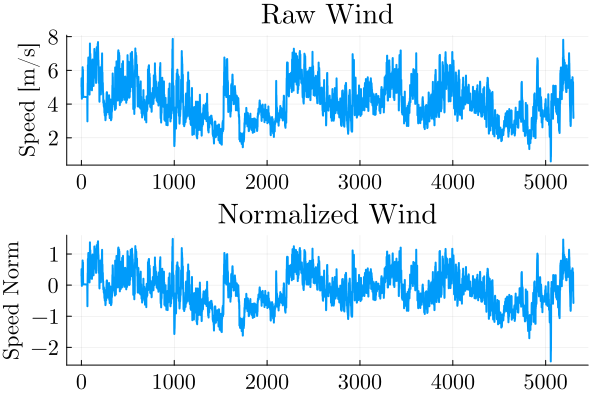

In [6]:
# Pull in wind data from csv
wind_data = CSV.read("2024-11-15_ergodic_data.csv", DataFrame)
raw_wind = wind_data.raw_wind
normal_wind = wind_data.normal_val

# Remove the initial zeroed values
clean_idx = findfirst(!iszero, raw_wind)
raw_wind = raw_wind[clean_idx:end]
normal_wind = normal_wind[clean_idx:end]
p1 = plot(raw_wind, label=false, title="Raw Wind", ylabel="Speed [m/s]")
p2 = plot(normal_wind, label=false, title="Normalized Wind", ylabel="Speed Norm")
plot(p1, p2, layout=(2,1))
savefig("lake_data_wind.png")
plot!()

# Common Variables

In [7]:
# setup the spatial and temporal kernels
σt = 2.0   # m/s
σs = 1.0   # m/s
lt = 0.25*60.0  # minutes
ls = 0.75   # km

kt = Matern(1/2, σt, lt)
ks = Matern(1/2, σs, ls)

# determine the spatial step size
dx = 0.05 # km

# create the spatial domain
xs = 0:dx:1.6
ys = 0:dx:1.9

grid_pts = vec([@SVector[x, y] for x in xs, y in ys]);

In [8]:
polygon_vertices = hcat(JordanLakeDomain.convex_polygon.vertices, JordanLakeDomain.convex_polygon.vertices[:, 1])  # Close the polygon
fuse_measurements_every_ΔT = 5.0/(60) # hours
recompute_controller_every_ΔT = 5.0 / (120.0*60) # minutes
σ_t = zeros(length(xs), length(ys));
w_rated_val = -0.5;

In [9]:
findnearest(A,x) = argmin(abs.(A .- x))

findnearest (generic function with 1 method)

In [10]:
kernel(x) = (σt^2) * (1 - exp(-x))
int_kernel(x) = (1 - exp(-x))
subkern(dt, dx) = (dt/lt) + (dx/ls)

subkern (generic function with 1 method)

# Convert all winds to weibull

In [11]:
normal_pdf(x; μ=0.0, σ=1.0) = 1/sqrt(2 * π * σ^2) * exp(-(x-μ)^2/(2 * σ^2))
normal_cdf(x; μ=0.0, σ=1.0) = 1/2 * ( 1 + erf( (x - μ) / sqrt(2*σ^2) ) )
normal_icdf(p; μ=0.0, σ=1.0) = μ + sqrt(2*σ^2) * erfinv(-1 + 2*p)

weibull_pdf(x; λ=1.0, k=2) = (k/λ) * (x / λ)^(k-1) * exp( - (x/λ)^k )
weibull_cdf(x; λ=1.0, k=2) = 1 - exp( - (x / λ)^k)
weibull_icdf(p; λ=1.0, k=2) = λ*(-log(1 - p))^(1/k)


function normal_to_weibull(x; μ, σ, λ, k)
    p = normal_cdf(x; μ=μ, σ=σ)
    z = weibull_icdf(p; λ=λ, k=k)
    return z
end

function weibull_to_normal(x; λ, k, μ, σ)
    p = weibull_cdf(x; λ=λ, k=k)
    z = normal_icdf(p; μ=μ, σ=σ)
    return z
end

weibull_to_normal (generic function with 1 method)

In [12]:
lambda = 5.126;
k = 2.3007;
mu = 0.0;
std_dev = 1.0;

synthetic_data_transformed = normal_to_weibull.(synthetic_data.data; μ = mu, σ = std_dev, λ = lambda, k = k);

w_hat_transformed = zeros(length(xs), length(ys), length(res_ergo_hp.w_hats));
for idx in 1:length(res_ergo_hp.w_hats)
    w_hat_transformed[:, :, idx] = normal_to_weibull.(res_ergo_hp.w_hats[idx]; μ = mu, σ = std_dev, λ = lambda, k = k);
end
println("Max Estimate: ", maximum(w_hat_transformed))

measurements_transformed = normal_to_weibull.(res_ergo_hp.measurements; μ = mu, σ = std_dev, λ = lambda, k = k);
println("Max wind speed: ", maximum(measurements_transformed))

Max Estimate: 10.384632879170338
Max wind speed: 7.867964171198192


In [73]:
size(res_ergo_hp.ergo_q_maps[1])

(33, 39)

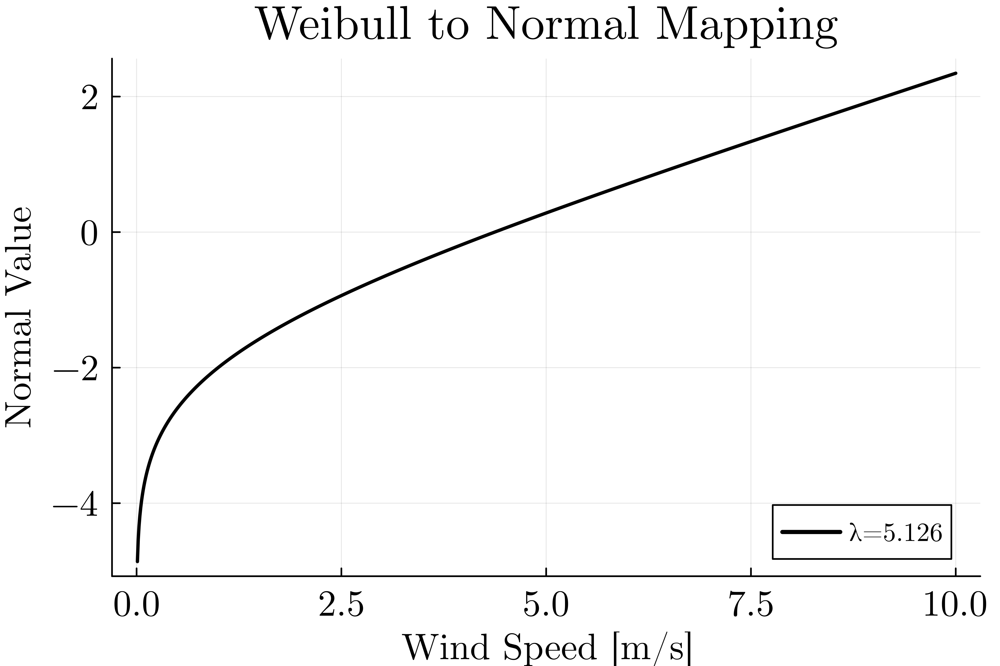

In [74]:
# Plot of the mapping from weibull to normal
plot(0:0.01:10, weibull_to_normal.(0:0.01:10; λ=lambda, k=k, μ=mu, σ=std_dev), label="λ=$(lambda)", ylabel="Normal Value", xlabel="Wind Speed [m/s]", title="Weibull to Normal Mapping", color="black", dpi=900)
savefig("weibull_to_normal_mapping.pdf")
plot!()

In [75]:
println("Synthetic Normal Maximum: ", maximum(synthetic_data.data))
println("Synthetic Weibull Maximum: ", maximum(synthetic_data_transformed))
println("Synthetic Normal Minimum: ", minimum(synthetic_data.data))
println("Synthetic Weibull Minimum: ", minimum(synthetic_data_transformed))

Synthetic Normal Maximum: 1.48654
Synthetic Weibull Maximum: 7.867964171198192
Synthetic Normal Minimum: -2.45305
Synthetic Weibull Minimum: 0.5970804068471761


In [76]:
println("Measured Normal Maximum: ", maximum(res_ergo_hp.measurements))
println("Measured Weibull Maximum: ", maximum(measurements_transformed))
println("Measured Normal Minimum: ", minimum(res_ergo_hp.measurements))
println("Measured Weibull Minimum: ", minimum(measurements_transformed))

Measured Normal Maximum: 1.48654
Measured Weibull Maximum: 7.867964171198192
Measured Normal Minimum: -2.45305
Measured Weibull Minimum: 0.5970804068471761


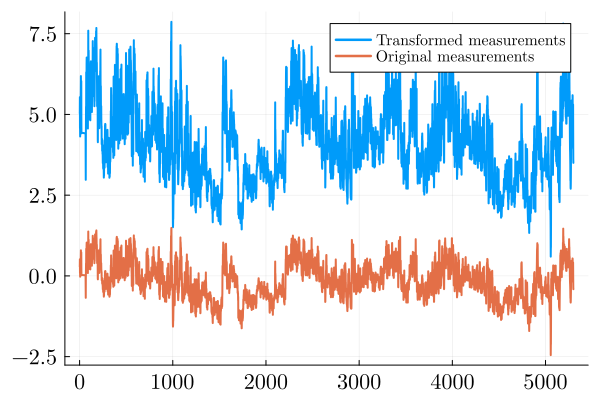

In [77]:
plot(measurements_transformed, label="Transformed measurements")
plot!(res_ergo_hp.measurements, label="Original measurements")

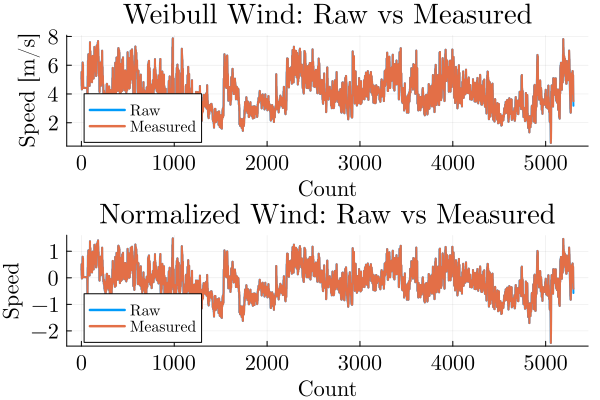

In [78]:
weibulls = plot(raw_wind, label="Raw")
weibulls = plot!(measurements_transformed, label="Measured")
weibulls = plot!(xlabel="Count", ylabel="Speed [m/s]", title="Weibull Wind: Raw vs Measured")

normals = plot(normal_wind, label="Raw")
normals = plot!(res_ergo_hp.measurements, label="Measured")
normals = plot!(xlabel="Count", ylabel="Speed", title="Normalized Wind: Raw vs Measured")

plot(weibulls, normals, layout=(2,1))
savefig("weibull_vs_normal_wind.png")
plot!()

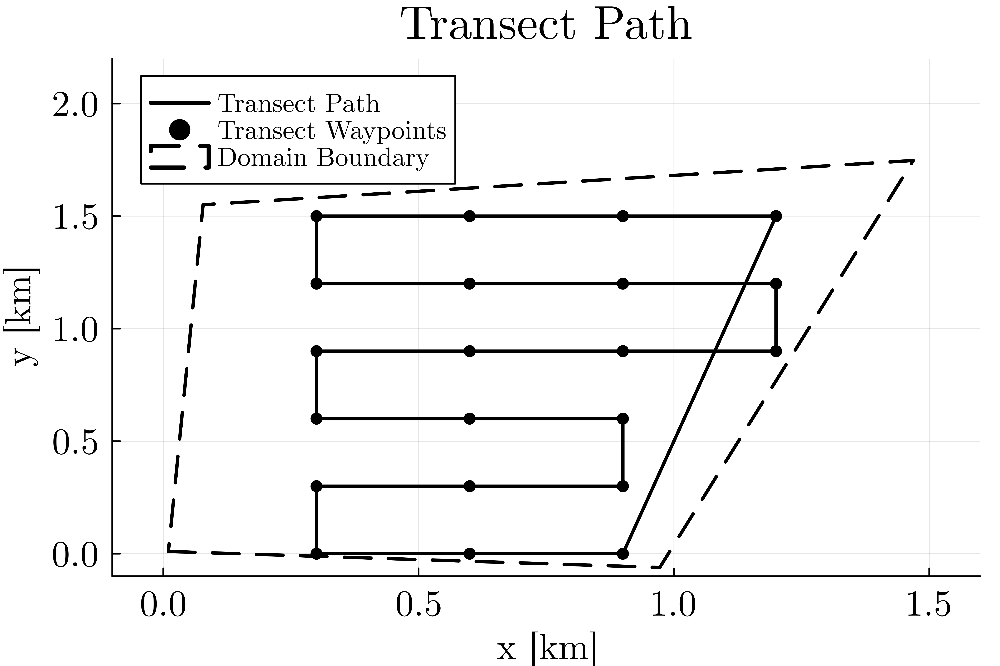

In [79]:
transect_xs = 0:0.3:2;
transect_ys = 0:0.3:2;
pts = vec([[x, y] for x in transect_xs, y in transect_ys]);
transect_pts = Transects.create_points(pts);
append!(transect_pts, [transect_pts[1]]);
plot([p[1] for p in transect_pts], [p[2] for p in transect_pts], label="Transect Path", color="black")
scatter!([p[1] for p in transect_pts], [p[2] for p in transect_pts], label="Transect Waypoints", color="black")
plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, lw = 2, linecolor = "black", linestyle=:dash, label="Domain Boundary")
xlims!(-0.1, 1.6)
ylims!(-0.1, 2.2)
xlabel!("x [km]")
ylabel!("y [km]")
plot!(legend=:topleft, dpi=900)
title!("Transect Path")
savefig("transect_path.pdf");
plot!()

# Processing

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\path_over_real_wind.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\path_over_real_wind.gif")
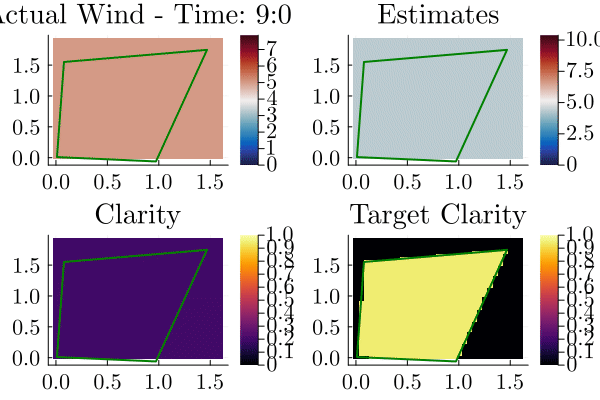

In [80]:
path_over_real_wind = @animate for n = 1:50:length(res_ergo_hp.ts)
    # Plot the actual wind and path
    plot()
    heatmap(synthetic_data.xs, synthetic_data.ys, synthetic_data_transformed[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    # for i=1:size(res_ergo_hp.xs)[1]
    #     x = [r[i][1] for r in res_ergo_hp.xs[1:n]]
    #     y = [r[i][2] for r in res_ergo_hp.xs[1:n]]
    #     plot!(x, y, linewidth=3, color=:black, label="w_rated_val = $(w_rated_val)")
    # end
    title!("Actual Wind - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    real_wind = plot!(clims=(0.0,maximum(synthetic_data_transformed)))

    # Plot the KF estimates
    plot()
    if res_ergo_hp.ts[n] in res_ergo_hp.w_hat_ts
        global w_hat_idx = findfirst(isequal(res_ergo_hp.ts[n]), res_ergo_hp.w_hat_ts)
    end
    heatmap(synthetic_data.xs, synthetic_data.ys, w_hat_transformed[:,:,w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,maximum(w_hat_transformed)))
    title!("Estimates")
    estimate_wind = plot!()

    # Plot the clarity map
    claritymap = heatmap(synthetic_data.xs, synthetic_data.ys, res_ergo_hp.ergo_q_maps[w_hat_idx]')
    # claritymap = heatmap(res_ergo_hp.ergo_q_maps[w_hat_idx]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Clarity")
    claritymap = plot!()

    # Plot the target clarity map
    plot()
    heatmap(synthetic_data.xs, synthetic_data.ys, res_ergo_hp.q_target_maps[n]'; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    title!("Target Clarity")
    target_clarity = plot!(clims=(0.0, 1.0))

    plot(real_wind, estimate_wind, claritymap, target_clarity, layout=(2,2))
    
end
gif(path_over_real_wind, "path_over_real_wind.gif")

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\clarity_deficit.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\clarity_deficit.gif")
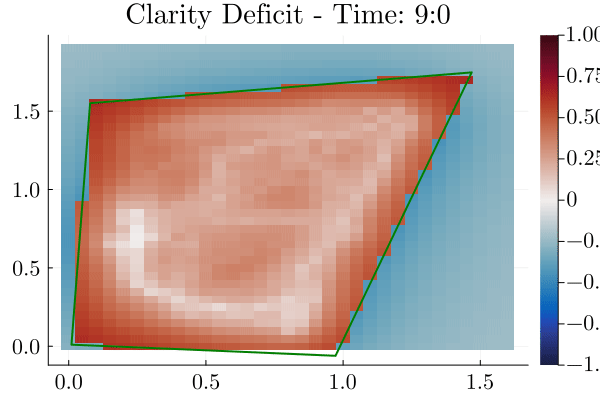

In [81]:
clarity_deficit = @animate for n = 1:50:length(res_ergo_hp.ts)
    # Calculate clarity deficit
    deficit = res_ergo_hp.q_target_maps[n]' .- res_ergo_hp.ergo_q_maps[w_hat_idx]'

    # Plot clarity deficit
    plot()
    heatmap(synthetic_data.xs, synthetic_data.ys, deficit, cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    title!("Clarity Deficit - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    plot!(clims=(-1.0, 1.0))
end
gif(clarity_deficit, "clarity_deficit.gif")

In [82]:
# Find indices where ts lines up with w_hat_ts
aligned_indices = findall(t -> t in res_ergo_hp.w_hat_ts, res_ergo_hp.ts)

# Extract the corresponding q_target_maps
aligned_q_target_maps = res_ergo_hp.q_target_maps[aligned_indices]
length(aligned_q_target_maps)

1766

In [83]:
length(res_ergo_hp.ergo_q_maps)

1766

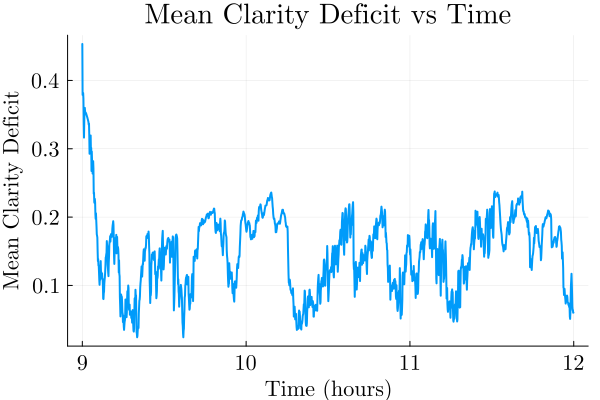

In [84]:
# Compute the mean clarity deficit per index
# mean_clarity_deficit = [mean(abs.(aligned_q_target_maps[i] .- res_ergo_hp.ergo_q_maps[i])) for i in 1:length(aligned_q_target_maps)]
mean_clarity_deficit = [mean(max.(0, aligned_q_target_maps[i] .- res_ergo_hp.ergo_q_maps[i])) for i in 1:length(aligned_q_target_maps)]

# Convert w_hat_ts to hours
w_hat_ts_hours = res_ergo_hp.w_hat_ts ./ 60
# Plot the mean clarity deficit
plot(w_hat_ts_hours, mean_clarity_deficit, xlabel="Time (hours)", ylabel="Mean Clarity Deficit", label=false, title="Mean Clarity Deficit vs Time", clims=(0, 1))

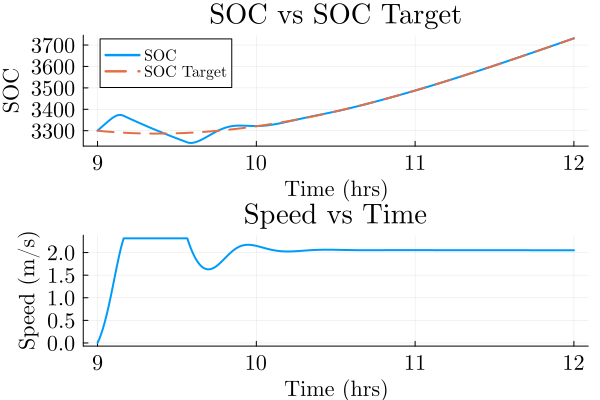

In [85]:
# Extract SOC data
soc_data = res_ergo_hp.bs

# Plot SOC data against SOC target
plot(ts_hrs, soc_data[2:end], label="SOC", xlabel="Time (hrs)", ylabel="SOC", lw=2)
plot!(ts_hrs, soc_target, label="SOC Target", lw=2, linestyle=:dash)
title!("SOC vs SOC Target")
soc_plot = plot!()

# Plot the speed vs Time
speed_plot = plot(ts_hrs, res_ergo_hp.speeds, label=false, xlabel="Time (hrs)", ylabel="Speed (m/s)", title="Speed vs Time", lw=2)

# Coplot
plot(soc_plot, speed_plot, layout=(2,1))
savefig("soc_speed_plot.png")
plot!()

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\realtime_error.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\realtime_error.gif")
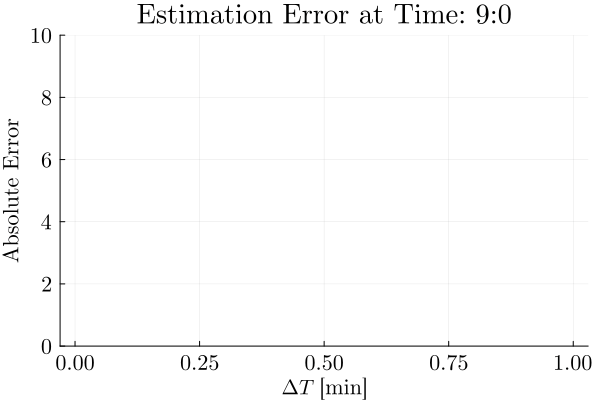

In [86]:
update_idxs = [t in res_ergo_hp.w_hat_ts ? 1 : 0 for t in res_ergo_hp.ts]
w_hat_idx = 1
measurement_val = []
estim_val = []
estim_dt = 10 # minutes

realtime_errors = @animate for n = 1:10:length(res_ergo_hp.ts)-1
    # Collect measurements
    push!(measurement_val, res_ergo_hp.measurements[n])
    x = res_ergo_hp.xs[n][end][1];
    y = res_ergo_hp.xs[n][end][2];

    # estim_idx = max(res_ergo_hp.ts[n] - estim_dt, res_ergo_hp.ts[1])
    estim_idx = res_ergo_hp.ts[n]
    new_idx = findnearest(res_ergo_hp.w_hat_ts, estim_idx)
    itp = linear_interpolation((xs, ys), res_ergo_hp.w_hats[new_idx])
    push!(estim_val, itp(x, y))

    errors = []
    for idx = res_ergo_hp.ts[n]:-0.01:max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt)
    # for idx = max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt):0.01:res_ergo_hp.ts[n]
        new_idx = findnearest(res_ergo_hp.w_hat_ts, idx)
        itp = linear_interpolation((xs, ys), res_ergo_hp.w_hats[new_idx])
        push!(errors, abs(res_ergo_hp.measurements[n] - itp(x,y)))
    end
    
    xrange = 0:0.01:res_ergo_hp.ts[n]-max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt)
    plot(xrange,errors, label=false)
    ylims!(0, 10)
    title!("Estimation Error at Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    xlabel!(L"$\Delta T$ [min]")
    ylabel!("Absolute Error")
end
gif(realtime_errors, "realtime_error.gif")

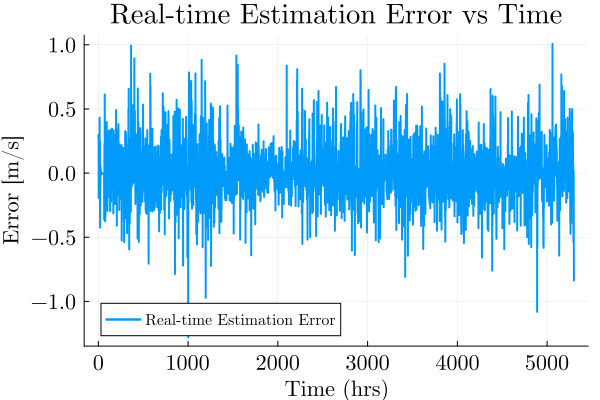

In [87]:
estimates_v_time = []
for n = 1:length(res_ergo_hp.ts)
    x = res_ergo_hp.xs[n][end][1];
    y = res_ergo_hp.xs[n][end][2];

    estim_idx = res_ergo_hp.ts[n]
    new_idx = findnearest(res_ergo_hp.w_hat_ts, estim_idx)
    itp = linear_interpolation((xs, ys), res_ergo_hp.w_hats[new_idx])
    push!(estimates_v_time, itp(x, y))
end

# Plot real-time estimation error
plot(res_ergo_hp.measurements .- estimates_v_time, label="Real-time Estimation Error", xlabel="Time (hrs)", ylabel="Error [m/s]", lw=2)
title!("Real-time Estimation Error vs Time")
savefig("realtime_estimation_error.png")
plot!()

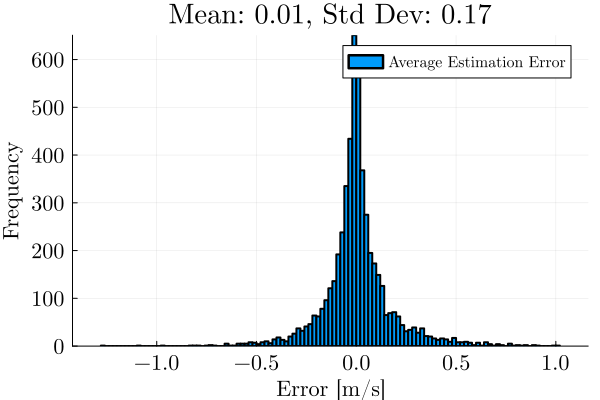

In [88]:
average_realtime_errors = res_ergo_hp.measurements .- estimates_v_time;
histogram(average_realtime_errors, label="Average Estimation Error", xlabel="Error [m/s]", ylabel="Frequency", lw=2)
title!("Mean: $(round(mean(average_realtime_errors), digits=2)), Std Dev: $(round(std(average_realtime_errors), digits=2))")
savefig("estimation_error_histogram.png")
plot!()

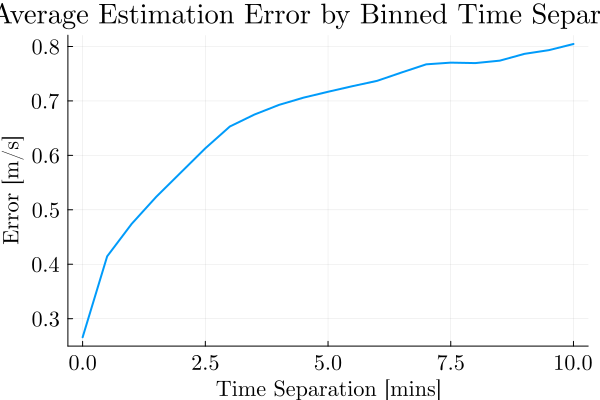

In [89]:
# Define the time bins
estim_dt = 10; # minutes
time_bins = 0:0.5:estim_dt
binned_errors = [Float64[] for _ in 1:length(time_bins)]

# Bin the errors based on time separation
for n = 1:length(res_ergo_hp.ts)
    x = res_ergo_hp.xs[n][end][1]
    y = res_ergo_hp.xs[n][end][2]
    for idx = res_ergo_hp.ts[n]:-0.01:max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt)
        new_idx = findnearest(res_ergo_hp.w_hat_ts, idx)
        itp = linear_interpolation((xs, ys), res_ergo_hp.w_hats[new_idx])
        error = abs(res_ergo_hp.measurements[n] - itp(x, y))
        time_sep = res_ergo_hp.ts[n] - idx
        bin_idx = findnearest(time_bins, time_sep)
        push!(binned_errors[bin_idx], error)
    end
end

# Calculate the average error for each bin
avg_binned_errors = [mean(errors) for errors in binned_errors if !isempty(errors)]

# Plot the average estimation error by binned time separation
plot(time_bins, avg_binned_errors, label=false, xlabel="Time Separation [mins]", ylabel="Error [m/s]", lw=2)
title!("Average Estimation Error by Binned Time Separation")
savefig("avg_estimation_error_by_time_separation.png")
plot!()

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\kern_error_reset.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\kern_error_reset.gif")
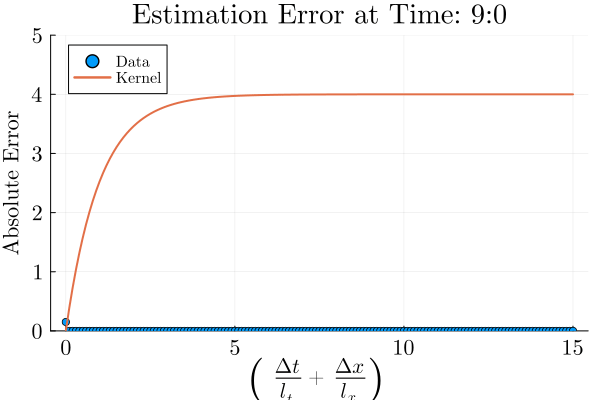

In [90]:
update_idxs = [t in res_ergo_hp.w_hat_ts ? 1 : 0 for t in res_ergo_hp.ts]
w_hat_idx = 1
measurement_val = []
estim_val = []
estim_dt = 30 # minutes


kern_error_reset = @animate for n = 1:10:length(res_ergo_hp.ts)-1
    # Collect measurements
    push!(measurement_val, res_ergo_hp.measurements[n])
    x = res_ergo_hp.xs[n][end][1];
    y = res_ergo_hp.xs[n][end][2];

    # estim_idx = max(res_ergo_hp.ts[n] - estim_dt, res_ergo_hp.ts[1])
    estim_idx = res_ergo_hp.ts[n]
    new_idx = findnearest(res_ergo_hp.w_hat_ts, estim_idx)
    itp = linear_interpolation((xs, ys), res_ergo_hp.w_hats[new_idx])
    push!(estim_val, itp(x, y))

    errors = []
    kern_vals = 0:0.1:15
    kern_bins = [zeros(1) for _ in 1:length(kern_vals)]
    
    for idx = res_ergo_hp.ts[n]:-0.01:max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt)
    # for idx = max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt):0.01:res_ergo_hp.ts[n]
        new_idx = findnearest(res_ergo_hp.w_hat_ts, idx)
        itp = linear_interpolation((xs, ys), res_ergo_hp.w_hats[new_idx])
        push!(errors, (res_ergo_hp.measurements[n] - itp(x,y))^2)


        # Get position at which estimate was made
        t_idx = findnearest(res_ergo_hp.ts, res_ergo_hp.w_hat_ts[new_idx])
        x_past = res_ergo_hp.xs[t_idx][end][1]
        y_past = res_ergo_hp.xs[t_idx][end][2]

        dx = sqrt((x - x_past)^2 + (y - y_past)^2);
        dt = abs(res_ergo_hp.ts[n] - res_ergo_hp.w_hat_ts[new_idx]);
        kern_val = kernel(subkern(dx, dt))
        kern_idx = findnearest(kern_vals, kern_val);
        push!(kern_bins[kern_idx], abs(res_ergo_hp.measurements[n] - itp(x,y)))

    end

  
    xrange = 0:0.01:res_ergo_hp.ts[n]-max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt)
    # plot(xrange,errors, label=false)
    scatter(kern_vals, mean.(kern_bins), label="Data")
    plot!(kern_vals, kernel.(kern_vals), label="Kernel")
    ylims!(0, 5)
    title!("Estimation Error at Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    xlabel!(L"$\left( \frac{\Delta t}{l_t} + \frac{\Delta x}{l_x} \right)$")
    ylabel!("Absolute Error")
end
gif(kern_error_reset, "kern_error_reset.gif")

# Transect Sim

In [91]:
# Load Transect Data
# transect_file_path = "20241115_transect_sim.jld2"
transect_file_path = "20241115_transect_lambdaparam_0_25.jld2"
f_transect = jldopen(transect_file_path, "r")
res_transect = f_transect["res_ergo_hp"]
synthetic_data_transect = f_transect["synthetic_data"]
soc_target_transect = f_transect["soc_target"]
ts_hrs_transect = f_transect["ts_hrs"]
close(f_transect)

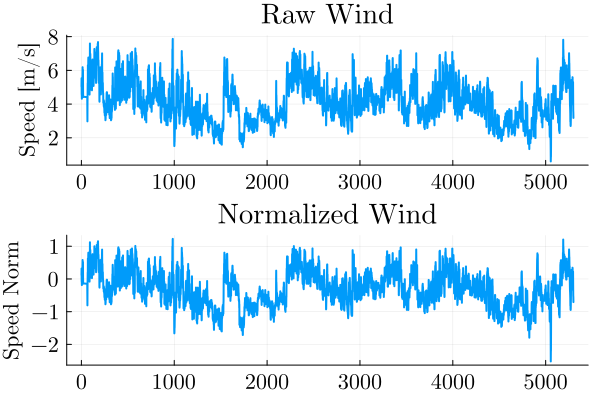

In [92]:
# Pull in wind data from csv
wind_transect = CSV.read("2024-11-15_transect_data.csv", DataFrame)
raw_wind_transect = wind_transect.raw_wind
normal_wind_transect = wind_transect.normal_val

# Remove the initial zeroed values
clean_idx = findfirst(!iszero, raw_wind_transect)
raw_wind_transect = raw_wind_transect[clean_idx:end]
normal_wind_transect = normal_wind_transect[clean_idx:end]
p1_transect = plot(raw_wind_transect, label=false, title="Raw Wind", ylabel="Speed [m/s]")
p2_transect = plot(normal_wind_transect, label=false, title="Normalized Wind", ylabel="Speed Norm")
plot(p1_transect, p2_transect, layout=(2,1))
savefig("lake_data_wind_transect.png")
plot!()

In [93]:
lambda = 5.126;
k = 2.3007;
mu = 0.0;
std_dev = 1.0;

synthetic_data_transformed_transect = normal_to_weibull.(synthetic_data_transect.data; μ = mu, σ = std_dev, λ = lambda, k = k);

w_hat_transformed_transect = zeros(length(xs), length(ys), length(res_transect.w_hats));
for idx in 1:length(res_transect.w_hats)
    w_hat_transformed_transect[:, :, idx] = normal_to_weibull.(res_transect.w_hats[idx]; μ = mu, σ = std_dev, λ = lambda, k = k);
end
println("Max Estimate: ", maximum(w_hat_transformed_transect))

measurements_transformed_transect = normal_to_weibull.(res_transect.measurements; μ = mu, σ = std_dev, λ = lambda, k = k);
println("Max wind speed: ", maximum(measurements_transformed_transect))

Max Estimate: 7.022142450926199
Max wind speed: 7.2301448961921615


In [94]:
println("Synthetic Normal Maximum: ", maximum(synthetic_data_transect.data))
println("Synthetic Weibull Maximum: ", maximum(synthetic_data_transformed_transect))
println("Synthetic Normal Minimum: ", minimum(synthetic_data_transect.data))
println("Synthetic Weibull Minimum: ", minimum(synthetic_data_transformed_transect))

Synthetic Normal Maximum: 1.22592
Synthetic Weibull Maximum: 7.2301448961921615
Synthetic Normal Minimum: -2.52201
Synthetic Weibull Minimum: 0.5486779771066945


In [95]:
println("Measured Normal Maximum: ", maximum(res_transect.measurements))
println("Measured Weibull Maximum: ", maximum(measurements_transformed_transect))
println("Measured Normal Minimum: ", minimum(res_transect.measurements))
println("Measured Weibull Minimum: ", minimum(measurements_transformed_transect))

Measured Normal Maximum: 1.22592
Measured Weibull Maximum: 7.2301448961921615
Measured Normal Minimum: -2.52201
Measured Weibull Minimum: 0.5486779771066945


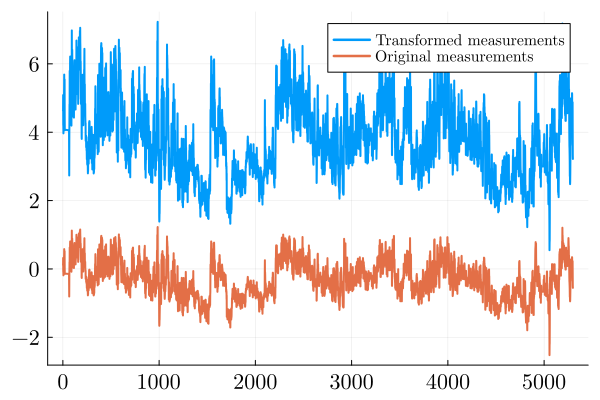

In [96]:
plot(measurements_transformed_transect, label="Transformed measurements")
plot!(res_transect.measurements, label="Original measurements")

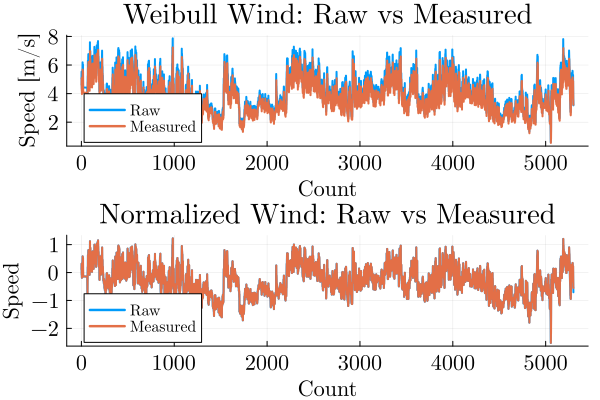

In [97]:
weibulls_transect = plot(raw_wind_transect, label="Raw")
weibulls_transect = plot!(measurements_transformed_transect, label="Measured")
weibulls_transect = plot!(xlabel="Count", ylabel="Speed [m/s]", title="Weibull Wind: Raw vs Measured")

normals_transect = plot(normal_wind_transect, label="Raw")
normals_transect = plot!(res_transect.measurements, label="Measured")
normals_transect = plot!(xlabel="Count", ylabel="Speed", title="Normalized Wind: Raw vs Measured")

plot(weibulls_transect, normals_transect, layout=(2,1))
savefig("weibull_vs_normal_wind_transect.png")
plot!()

## Transect Processing

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\path_over_real_wind_transect.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\path_over_real_wind_transect.gif")
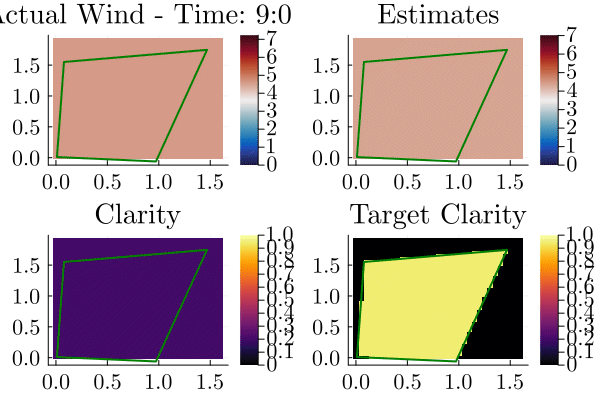

In [98]:
path_over_real_wind_transect = @animate for n = 1:50:length(res_transect.ts)
    # Plot the actual wind and path
    plot()
    heatmap(synthetic_data_transect.xs, synthetic_data_transect.ys, synthetic_data_transformed_transect[:,:,n]', cmap = :balance; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    # for i=1:size(res_transect.xs)[1]
    #     x = [r[i][1] for r in res_transect.xs[1:n]]
    #     y = [r[i][2] for r in res_transect.xs[1:n]]
    #     plot!(x, y, linewidth=3, color=:black, label="w_rated_val = $(w_rated_val)")
    # end
    title!("Actual Wind - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    real_wind = plot!(clims=(0.0,maximum(synthetic_data_transformed_transect)))

    # Plot the KF estimates
    plot()
    if res_transect.ts[n] in res_transect.w_hat_ts
        global w_hat_idx = findfirst(isequal(res_transect.ts[n]), res_transect.w_hat_ts)
    end
    heatmap(synthetic_data_transect.xs, synthetic_data_transect.ys, w_hat_transformed_transect[:,:,w_hat_idx]', cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,maximum(w_hat_transformed_transect)))
    title!("Estimates")
    estimate_wind = plot!()

    # Plot the clarity map
    claritymap = heatmap(synthetic_data_transect.xs, synthetic_data_transect.ys, res_transect.ergo_q_maps[w_hat_idx]')
    # claritymap = heatmap(res_transect.ergo_q_maps[w_hat_idx]')
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    plot!(clims=(0.0,1.0))
    title!("Clarity")
    claritymap = plot!()

    # Plot the target clarity map
    plot()
    heatmap(synthetic_data_transect.xs, synthetic_data_transect.ys, res_transect.q_target_maps[n]'; plottype=:wx)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    title!("Target Clarity")
    target_clarity = plot!(clims=(0.0, 1.0))

    plot(real_wind, estimate_wind, claritymap, target_clarity, layout=(2,2))
    
end
gif(path_over_real_wind_transect, "path_over_real_wind_transect.gif")

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\clarity_deficit_transect.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\clarity_deficit_transect.gif")
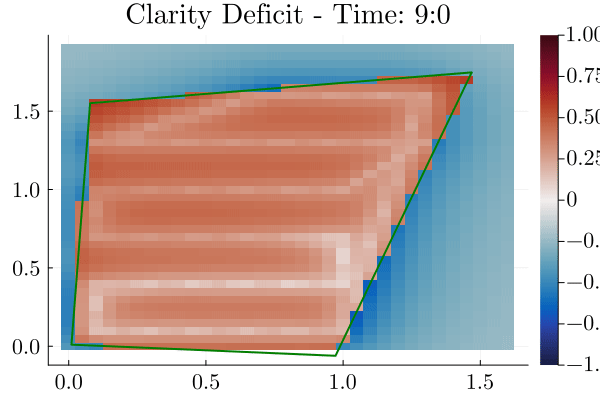

In [99]:
clarity_deficit_transect = @animate for n = 1:50:length(res_transect.ts)
    # Calculate clarity deficit
    deficit = res_transect.q_target_maps[n]' .- res_transect.ergo_q_maps[w_hat_idx]'

    # Plot clarity deficit
    plot()
    heatmap(synthetic_data_transect.xs, synthetic_data_transect.ys, deficit, cmap=:balance)
    plot!(polygon_vertices[1, :], polygon_vertices[2, :], seriestype=:shape, fillalpha=0.0, label="", lw = 2, linecolor = "green")
    title!("Clarity Deficit - Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    plot!(clims=(-1.0, 1.0))
end
gif(clarity_deficit_transect, "clarity_deficit_transect.gif")

In [100]:
# Find indices where ts lines up with w_hat_ts
aligned_indices_transect = findall(t -> t in res_transect.w_hat_ts, res_transect.ts)

# Extract the corresponding q_target_maps
aligned_q_target_maps_transect = res_transect.q_target_maps[aligned_indices]
length(aligned_q_target_maps_transect)

1766

In [101]:
length(res_transect.ergo_q_maps)

1766

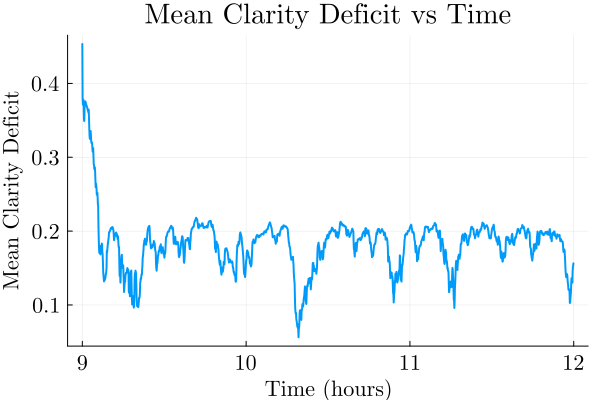

In [102]:
# Compute the mean clarity deficit per index
# mean_clarity_deficit_transect = [mean(abs.(aligned_q_target_maps_transect[i] .- res_transect.ergo_q_maps[i])) for i in 1:length(aligned_q_target_maps_transect)]
mean_clarity_deficit_transect = [mean(max.(0, aligned_q_target_maps_transect[i] .- res_transect.ergo_q_maps[i])) for i in 1:length(aligned_q_target_maps_transect)]

# Convert w_hat_ts to hours
w_hat_ts_hours_transect = res_transect.w_hat_ts ./ 60
# Plot the mean clarity deficit
plot(w_hat_ts_hours_transect, mean_clarity_deficit_transect, xlabel="Time (hours)", ylabel="Mean Clarity Deficit", label=false, title="Mean Clarity Deficit vs Time", clims=(0,1))

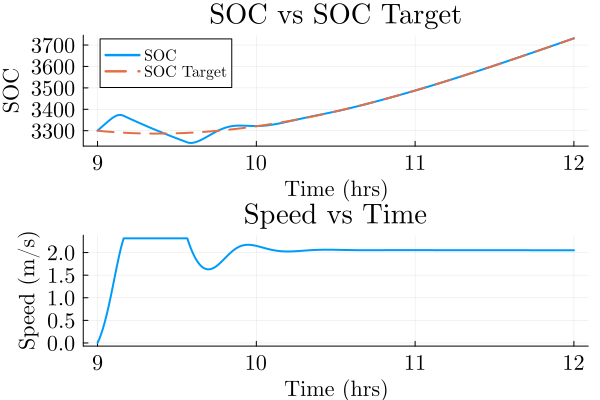

In [103]:
# Extract SOC data
soc_data_transect = res_transect.bs

# Plot SOC data against SOC target
plot(ts_hrs_transect, soc_data_transect[2:end], label="SOC", xlabel="Time (hrs)", ylabel="SOC", lw=2)
plot!(ts_hrs_transect, soc_target_transect, label="SOC Target", lw=2, linestyle=:dash)
title!("SOC vs SOC Target")
soc_plot_transect = plot!()

# Plot the speed vs Time
speed_plot_transect = plot(ts_hrs_transect, res_transect.speeds, label=false, xlabel="Time (hrs)", ylabel="Speed (m/s)", title="Speed vs Time", lw=2)

# Coplot
plot(soc_plot_transect, speed_plot_transect, layout=(2,1))
savefig("soc_speed_plot_transect.png")
plot!()

┌ Info: Saved animation to c:\Users\kavin\Documents\Research\CPS\adaptive-ocean-exploration-sim\lakedata_sim\realtime_error_transect.gif
└ @ Plots C:\Users\kavin\.julia\packages\Plots\Ec1L1\src\animation.jl:156


Plots.AnimatedGif("c:\\Users\\kavin\\Documents\\Research\\CPS\\adaptive-ocean-exploration-sim\\lakedata_sim\\realtime_error_transect.gif")
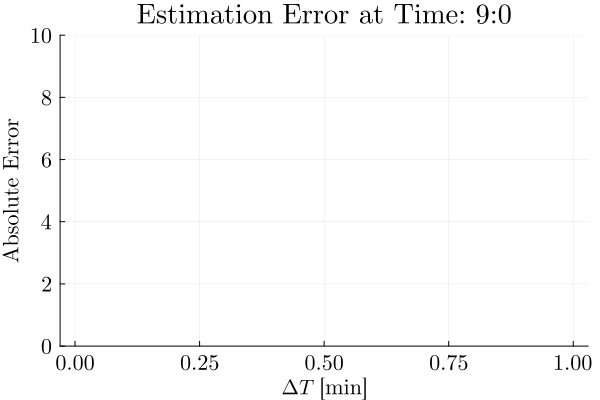

In [104]:
update_idxs_transect = [t in res_transect.w_hat_ts ? 1 : 0 for t in res_transect.ts]
w_hat_idx_transect = 1
measurement_val_transect = []
estim_val_transect = []
estim_dt_transect = 10 # minutes

realtime_errors_transect = @animate for n = 1:10:length(res_transect.ts)-1
    # Collect measurements
    push!(measurement_val_transect, res_transect.measurements[n])
    x = res_transect.xs[n][end][1];
    y = res_transect.xs[n][end][2];

    # estim_idx = max(res_ergo_hp.ts[n] - estim_dt, res_ergo_hp.ts[1])
    estim_idx = res_transect.ts[n]
    new_idx = findnearest(res_transect.w_hat_ts, estim_idx)
    itp = linear_interpolation((xs, ys), res_transect.w_hats[new_idx])
    push!(estim_val_transect, itp(x, y))

    errors = []
    for idx = res_transect.ts[n]:-0.01:max(res_transect.ts[1], res_transect.ts[n] - estim_dt_transect)
    # for idx = max(res_ergo_hp.ts[1], res_ergo_hp.ts[n] - estim_dt):0.01:res_ergo_hp.ts[n]
        new_idx = findnearest(res_transect.w_hat_ts, idx)
        itp = linear_interpolation((xs, ys), res_transect.w_hats[new_idx])
        push!(errors, abs(res_transect.measurements[n] - itp(x,y)))
    end
    
    xrange = 0:0.01:res_transect.ts[n]-max(res_transect.ts[1], res_transect.ts[n] - estim_dt_transect)
    plot(xrange,errors, label=false)
    ylims!(0, 10)
    title!("Estimation Error at Time: $(Int(floor(ts_hrs[n]))):$(Int(floor(mod(ts_hrs[n],1)*60)))")
    xlabel!(L"$\Delta T$ [min]")
    ylabel!("Absolute Error")
end
gif(realtime_errors_transect, "realtime_error_transect.gif")

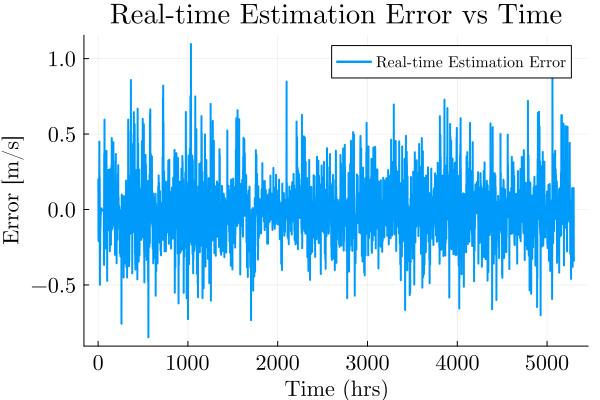

In [105]:
estimates_v_time_transect = []
for n = 1:length(res_transect.ts)
    x = res_transect.xs[n][end][1];
    y = res_transect.xs[n][end][2];

    estim_idx = res_transect.ts[n]
    new_idx = findnearest(res_transect.w_hat_ts, estim_idx)
    itp = linear_interpolation((xs, ys), res_transect.w_hats[new_idx])
    push!(estimates_v_time_transect, itp(x, y))
end

# Plot real-time estimation error
plot(res_transect.measurements .- estimates_v_time_transect, label="Real-time Estimation Error", xlabel="Time (hrs)", ylabel="Error [m/s]", lw=2)
title!("Real-time Estimation Error vs Time")
savefig("realtime_estimation_error_transect.png")
plot!()

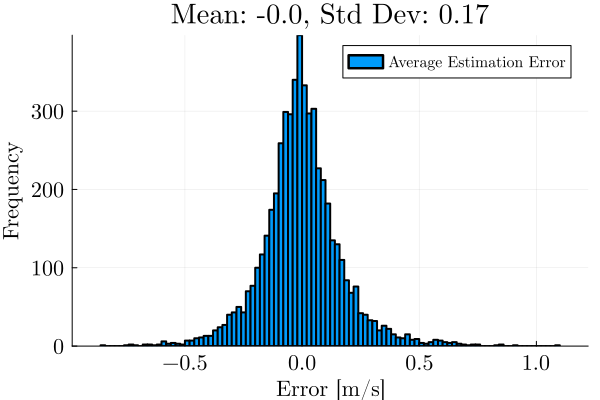

In [106]:
average_realtime_errors_transect = res_transect.measurements .- estimates_v_time_transect;
histogram(average_realtime_errors_transect, label="Average Estimation Error", xlabel="Error [m/s]", ylabel="Frequency", lw=2)
title!("Mean: $(round(mean(average_realtime_errors_transect), digits=2)), Std Dev: $(round(std(average_realtime_errors_transect), digits=2))")
savefig("estimation_error_histogram_transect.png")
plot!()

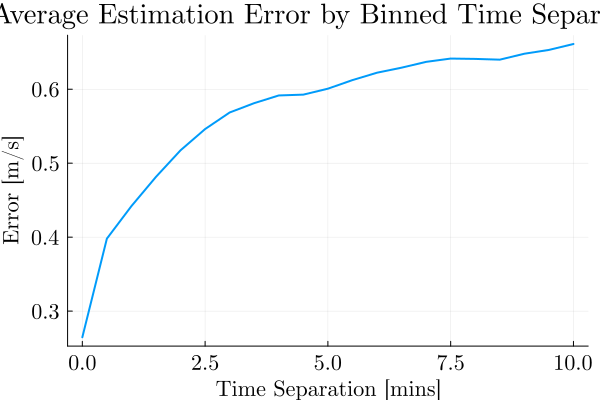

In [107]:
# Define the time bins
estim_dt = 10; # minutes
time_bins = 0:0.5:estim_dt
binned_errors_transect = [Float64[] for _ in 1:length(time_bins)]

# Bin the errors based on time separation
for n = 1:length(res_transect.ts)
    x = res_transect.xs[n][end][1]
    y = res_transect.xs[n][end][2]
    for idx = res_transect.ts[n]:-0.01:max(res_transect.ts[1], res_transect.ts[n] - estim_dt)
        new_idx = findnearest(res_transect.w_hat_ts, idx)
        itp = linear_interpolation((xs, ys), res_transect.w_hats[new_idx])
        error = abs(res_transect.measurements[n] - itp(x, y))
        time_sep = res_transect.ts[n] - idx
        bin_idx = findnearest(time_bins, time_sep)
        push!(binned_errors[bin_idx], error)
    end
end

# Calculate the average error for each bin
avg_binned_errors_transect = [mean(errors) for errors in binned_errors if !isempty(errors)]

# Plot the average estimation error by binned time separation
plot(time_bins, avg_binned_errors_transect, label=false, xlabel="Time Separation [mins]", ylabel="Error [m/s]", lw=2)
title!("Average Estimation Error by Binned Time Separation")
savefig("avg_estimation_error_by_time_separation_transect.png")
plot!()

# Co Plots and Comparison

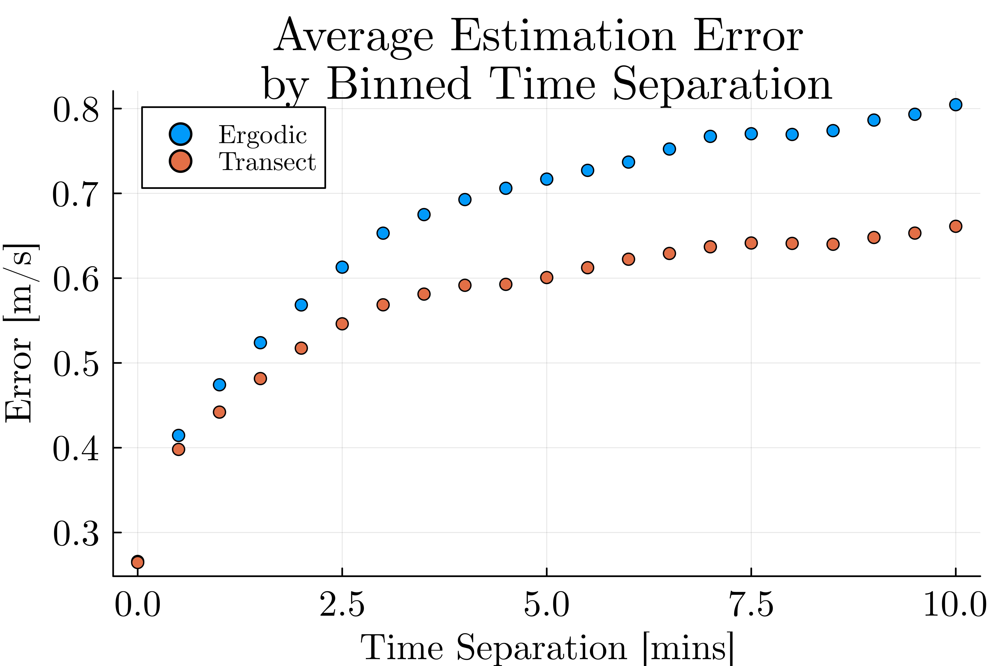

In [108]:
# Plot the average estimation error by binned time separation for both ergodic and transect
scatter(time_bins, avg_binned_errors, label="Ergodic", xlabel="Time Separation [mins]", ylabel="Error [m/s]", lw=2)
scatter!(time_bins, avg_binned_errors_transect, label="Transect", lw=2)
title!("Average Estimation Error \nby Binned Time Separation")
plot!(dpi=900)
savefig("avg_estimation_error_comparison.pdf")
plot!()

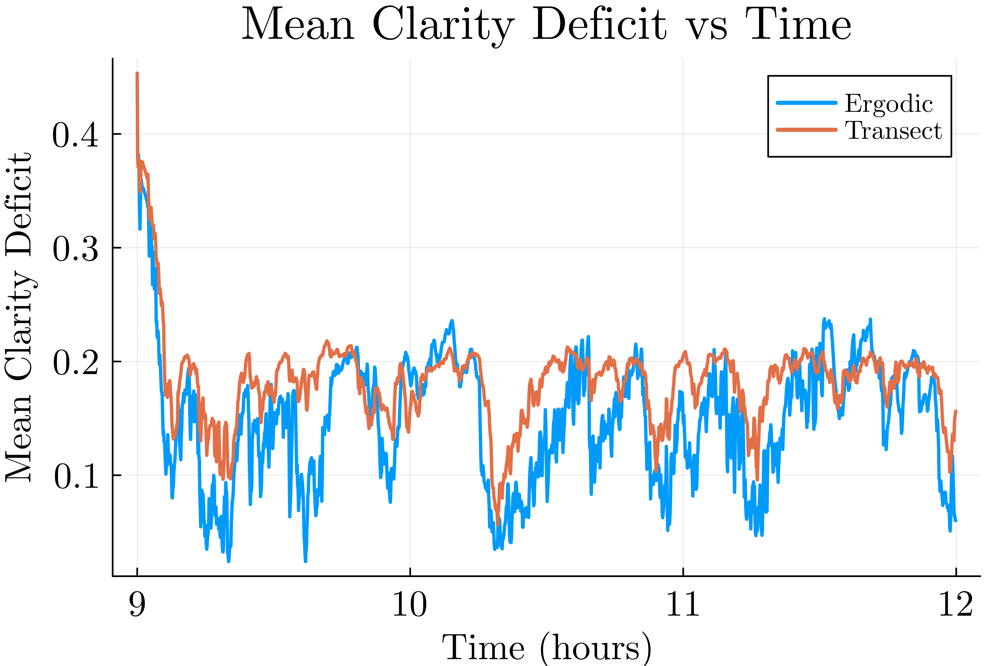

In [113]:
# Co-plot the mean clarity deficit for ergodic and transect
plot(w_hat_ts_hours, mean_clarity_deficit, label="Ergodic", xlabel="Time (hours)", ylabel="Mean Clarity Deficit", lw=2)
plot!(w_hat_ts_hours_transect, mean_clarity_deficit_transect, label="Transect", lw=2)
title!("Mean Clarity Deficit vs Time")
plot!(dpi=900)
savefig("mean_clarity_deficit_comparison.pdf")
plot!()

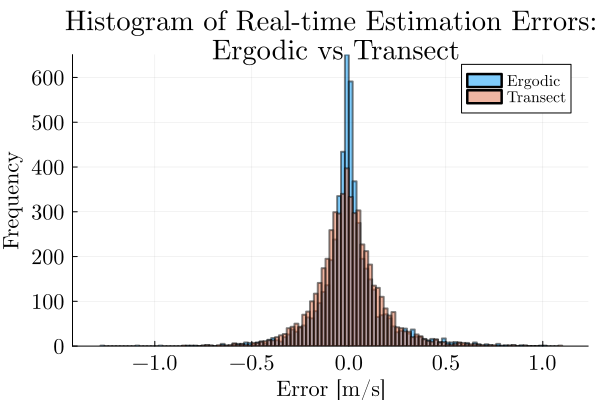

In [110]:
# Co-plot the histograms of real-time errors for ergodic and transect
histogram(average_realtime_errors, label="Ergodic", xlabel="Error [m/s]", ylabel="Frequency", lw=2, alpha=0.5)
histogram!(average_realtime_errors_transect, label="Transect", lw=2, alpha=0.5)
title!("Histogram of Real-time Estimation Errors:\n Ergodic vs Transect")
savefig("realtime_error_histogram_comparison.png")
plot!()

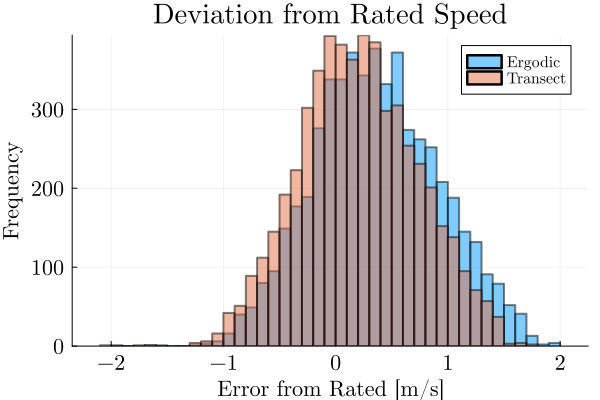

In [111]:
ergo_w_rated_val = -0.5;
transect_w_rated_val = -0.5;
ergo_error_from_rated = [res_ergo_hp.measurements[n] - ergo_w_rated_val for n in 1:length(res_ergo_hp.measurements)]
transect_error_from_rated = [res_transect.measurements[n] - transect_w_rated_val  for n in 1:length(res_transect.measurements)]

histogram(ergo_error_from_rated, label="Ergodic", xlabel="Error from Rated [m/s]", ylabel="Frequency", lw=2, alpha=0.5)
histogram!(transect_error_from_rated, label="Transect", lw=2, alpha=0.5)
title!("Deviation from Rated Speed")
savefig("error_from_rated_histogram_comparison.png")
plot!()

In [112]:
# Calculate mean and standard deviation for ergodic error from rated
ergo_mean_error_from_rated = mean(ergo_error_from_rated)
ergo_std_error_from_rated = std(ergo_error_from_rated)

# Calculate mean and standard deviation for transect error from rated
transect_mean_error_from_rated = mean(transect_error_from_rated)
transect_std_error_from_rated = std(transect_error_from_rated)

# Print the statistics
println("Ergodic Error from Rated - Mean: ", round(ergo_mean_error_from_rated, digits=2), ", Std Dev: ", round(ergo_std_error_from_rated, digits=2))
println("Transect Error from Rated - Mean: ", round(transect_mean_error_from_rated, digits=2), ", Std Dev: ", round(transect_std_error_from_rated, digits=2))

Ergodic Error from Rated - Mean: 0.37, Std Dev: 0.56
Transect Error from Rated - Mean: 0.21, Std Dev: 0.53
